# ESC 113 Engineering Coding Project
# USGS Earthquake Data Analysis - November 2026


In [38]:
from pathlib import Path
from urllib.request import urlretrieve
import pandas as pd
import matplotlib.pyplot as plt

In [39]:
folder = Path.cwd()
csv_file = folder / "earthquakes_nov_2026.csv"


In [40]:
url = (
    "https://earthquake.usgs.gov/fdsnws/event/1/query?"
    "format=csv&starttime=2026-09-01"
    "&endtime=2026-10-01&minmagnitude=4"
)

In [41]:
# Download earthquake data
if not csv_file.exists():
    print("Downloading earthquake data...")
    urlretrieve(url, csv_file)

In [42]:

# Read earthquake data
df = pd.read_csv(csv_file)

In [43]:
print("\nFIRST FIVE ROWS")
print(df.head())


FIRST FIVE ROWS
                       time  latitude  longitude  depth  mag magType  nst  \
0  2026-09-30T23:20:51.658Z  -19.4287   -69.5395  97.88  4.0      mb   15   
1  2026-09-30T23:12:46.375Z  -21.1728   168.5056  10.00  4.4      mb   15   
2  2026-09-30T22:12:09.936Z  -21.3854   168.5187  10.00  4.4      mb   17   
3  2026-09-30T21:55:26.296Z    9.7776   -86.4861   8.00  5.6     mww  111   
4  2026-09-30T21:16:53.444Z   35.6322   140.8573  35.00  4.4      mb   33   

   gap   dmin   rms  ...                   updated  \
0  110  0.796  0.73  ...  2026-10-15T03:37:54.040Z   
1  161  1.738  0.53  ...  2026-10-15T03:24:03.040Z   
2  164  1.575  0.57  ...  2026-10-08T04:07:13.040Z   
3   63  1.072  0.65  ...  2026-10-08T03:38:55.230Z   
4  137  2.329  0.78  ...  2026-10-22T05:21:15.040Z   

                                place        type horizontalError depthError  \
0           17 km SW of Camiña, Chile  earthquake            5.43      6.834   
1  77 km ENE of Tadine, New Caledon

In [44]:
print("\nTOTAL RECORDS")
print(len(df))



TOTAL RECORDS
1232


In [45]:
print("\nMISSING VALUES")
print(df.isnull().sum())


MISSING VALUES
time               0
latitude           0
longitude          0
depth              0
mag                0
magType            0
nst                0
gap                0
dmin               0
rms                0
net                0
id                 0
updated            0
place              0
type               0
horizontalError    2
depthError         0
magError           3
magNst             2
status             0
locationSource     0
magSource          0
dtype: int64


In [46]:
# Select earthquake events
df = df[df["type"] == "earthquake"].copy()

In [47]:
df["mag"] = pd.to_numeric(df["mag"], errors="coerce")
df["depth"] = pd.to_numeric(df["depth"], errors="coerce")
df["time"] = pd.to_datetime(df["time"], utc=True)

In [48]:
df = df.dropna(subset=["mag", "depth", "time"])

In [49]:
# Calculate earthquake statistics
print("\nEARTHQUAKE STATISTICS")
print("Total earthquakes:", len(df))
print("Average magnitude:", round(df["mag"].mean(), 2))
print("Largest magnitude:", df["mag"].max())
print("Smallest magnitude:", df["mag"].min())
print("Average depth:", round(df["depth"].mean(), 2))
print("Deepest earthquake:", df["depth"].max())
print("Shallowest earthquake:", df["depth"].min())



EARTHQUAKE STATISTICS
Total earthquakes: 1232
Average magnitude: 4.53
Largest magnitude: 6.7
Smallest magnitude: 4.0
Average depth: 74.8
Deepest earthquake: 665.057
Shallowest earthquake: 5.0


In [50]:
# Classify earthquakes by magnitude
def magnitude_class(magnitude):
    if magnitude < 4:
        return "Below 4"
    elif magnitude < 5:
        return "4.0-4.9"
    elif magnitude < 6:
        return "5.0-5.9"
    elif magnitude < 7:
        return "6.0-6.9"
    else:
        return "7.0+"


In [51]:
# Classify earthquakes by depth
def depth_class(depth):
    if depth < 70:
        return "Shallow"
    elif depth <= 300:
        return "Intermediate"
    else:
        return "Deep"


In [52]:
# Engineering screening function
def engineering_flag(magnitude, depth):
    if magnitude >= 5:
        return True
    elif magnitude >= 4 and depth < 50:
        return True
    else:
        return False


In [53]:
df["magnitude_category"] = df["mag"].apply(magnitude_class)
df["depth_category"] = df["depth"].apply(depth_class)


In [54]:
df["engineering_flag"] = df.apply(
    lambda row: engineering_flag(row["mag"], row["depth"]),
    axis=1
)


In [55]:
print("\nMAGNITUDE CLASSIFICATION")
print(df["magnitude_category"].value_counts())



MAGNITUDE CLASSIFICATION
magnitude_category
4.0-4.9    1068
5.0-5.9     158
6.0-6.9       6
Name: count, dtype: int64


In [56]:
print("\nDEPTH CLASSIFICATION")
print(df["depth_category"].value_counts())



DEPTH CLASSIFICATION
depth_category
Shallow         891
Intermediate    263
Deep             78
Name: count, dtype: int64


In [57]:
print("\nENGINEERING SCREENING")
print("Flagged earthquakes:", df["engineering_flag"].sum())


ENGINEERING SCREENING
Flagged earthquakes: 838


In [58]:
# Find largest and deepest earthquakes
largest = df.loc[df["mag"].idxmax()]
deepest = df.loc[df["depth"].idxmax()]


In [59]:
print("\nLARGEST EARTHQUAKE")
print(largest[["time", "mag", "depth", "place"]])



LARGEST EARTHQUAKE
time       2026-09-25 21:23:03.906000+00:00
mag                                     6.7
depth                                  10.0
place    74 km ENE of Tadine, New Caledonia
Name: 294, dtype: object


In [60]:

print("\nDEEPEST EARTHQUAKE")
print(deepest[["time", "mag", "depth", "place"]])



DEEPEST EARTHQUAKE
time     2026-09-20 02:50:09.824000+00:00
mag                                   4.2
depth                             665.057
place                      Vanuatu region
Name: 510, dtype: object


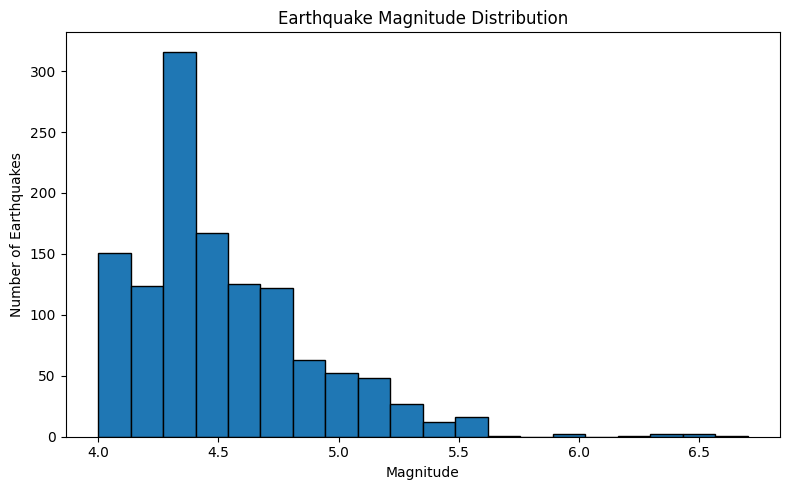

In [61]:

# Graph 1: Magnitude histogram
plt.figure(figsize=(8, 5))
plt.hist(df["mag"], bins=20, edgecolor="black")
plt.title("Earthquake Magnitude Distribution")
plt.xlabel("Magnitude")
plt.ylabel("Number of Earthquakes")
plt.tight_layout()
plt.savefig("graph1_magnitude.png")
plt.show()

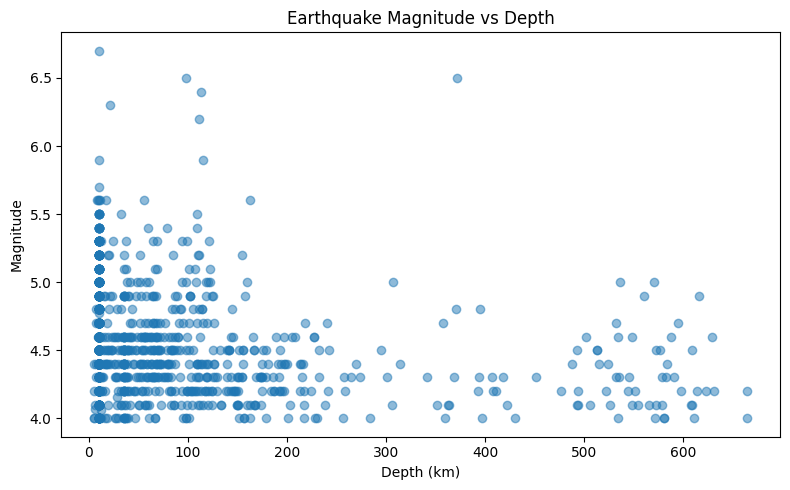

In [62]:

# Graph 2: Magnitude versus depth
plt.figure(figsize=(8, 5))
plt.scatter(df["depth"], df["mag"], alpha=0.5)
plt.title("Earthquake Magnitude vs Depth")
plt.xlabel("Depth (km)")
plt.ylabel("Magnitude")
plt.tight_layout()
plt.savefig("graph2_depth_magnitude.png")
plt.show()

In [63]:
# Graph 3: Magnitude categories
categories = ["4.0-4.9", "5.0-5.9", "6.0-6.9", "7.0+"]
counts = df["magnitude_category"].value_counts()
values = [counts.get(category, 0) for category in categories]


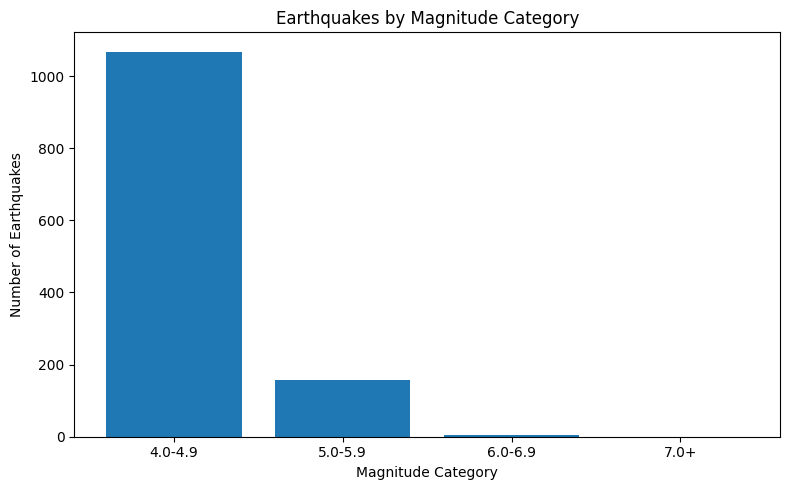

In [64]:
plt.figure(figsize=(8, 5))
plt.bar(categories, values)
plt.title("Earthquakes by Magnitude Category")
plt.xlabel("Magnitude Category")
plt.ylabel("Number of Earthquakes")
plt.tight_layout()
plt.savefig("graph3_categories.png")
plt.show()


In [65]:
# Graph 4: Earthquakes per day
df["date"] = df["time"].dt.date
daily_counts = df.groupby("date").size()


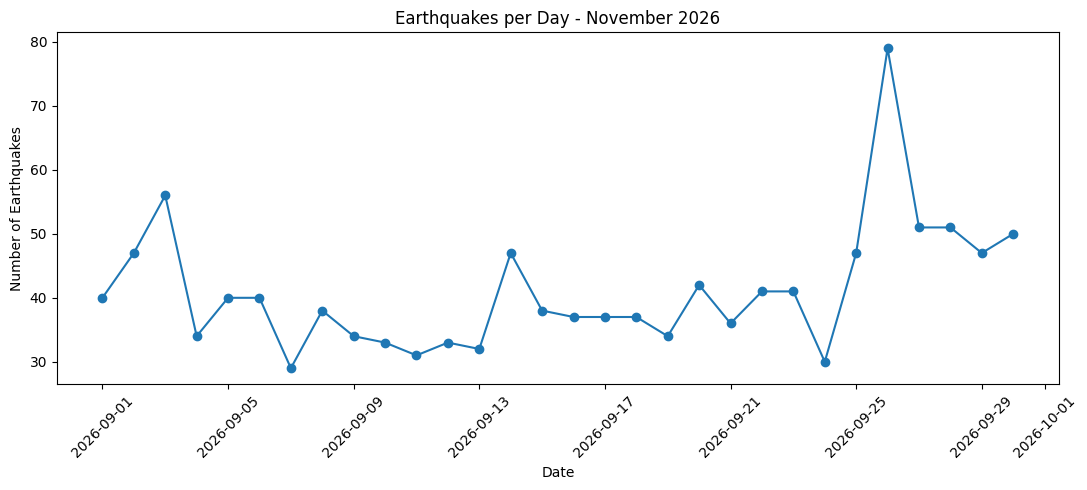

In [76]:
plt.figure(figsize=(11, 5))
plt.plot(daily_counts.index, daily_counts.values, marker="o")
plt.title("Earthquakes per Day - November 2026")
plt.xlabel("Date")
plt.ylabel("Number of Earthquakes")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("graph4_daily_earthquakes.png")
plt.show()


In [67]:
# Save analyzed data
df.to_csv("earthquakes_analyzed.csv", index=False)


In [68]:

print("Magnitude categories:")
print(df["magnitude_category"].value_counts())


Magnitude categories:
magnitude_category
4.0-4.9    1068
5.0-5.9     158
6.0-6.9       6
Name: count, dtype: int64


In [69]:

print("\nDepth categories:")
print(df["depth_category"].value_counts())



Depth categories:
depth_category
Shallow         891
Intermediate    263
Deep             78
Name: count, dtype: int64


In [70]:
print("\nLargest earthquake:")
print(df.loc[df["mag"].idxmax(),
             ["time", "mag", "depth", "place"]])



Largest earthquake:
time       2026-09-25 21:23:03.906000+00:00
mag                                     6.7
depth                                  10.0
place    74 km ENE of Tadine, New Caledonia
Name: 294, dtype: object


In [71]:

print("\nDaily peak:")
daily = df.groupby(df["time"].dt.date).size()
print(daily.idxmax(), daily.max())



Daily peak:
2026-09-26 79


In [72]:
print("\nEngineering screening:")
print(df["engineering_flag"].value_counts())



Engineering screening:
engineering_flag
True     838
False    394
Name: count, dtype: int64


In [73]:

from google.colab import files

files.download("graph1_magnitude.png")
files.download("graph2_depth_magnitude.png")
files.download("graph3_categories.png")
files.download("graph4_daily_earthquakes.png")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [74]:
from google.colab import files

files.download("earthquakes_analyzed.csv")
files.download("earthquakes_nov_2026.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>